<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# What does a stricter PII threshold actually remove?

Detect spans in a short synthetic note, measure how much text they cover without double-counting overlaps, and compare the selected threshold with the worker’s redaction output. Raising a detector threshold removes lower-scoring findings; it does not necessarily produce safer text.

**All names, contact strings and prose here are invented.** The example domain and demonstration phone number are not records of a real person. This is a reproducible inspection exercise, not an accuracy benchmark or proof of anonymization. The English Presidio recognizers and pinned small spaCy model run locally through the real VGI worker.

## Choose the review threshold

`SCORE_THRESHOLD` accepts a number from **0 to 1**, inclusive; default **0.5**. Scores are recognizer confidence values, **not calibrated probabilities of sensitivity**. Restart and run all after changing the threshold. Only `detect_pii` accepts this threshold; the scalar `redact`, `anonymize` and `has_pii` functions always use the worker’s fixed **0.5** threshold.

In [1]:
SCORE_THRESHOLD = 0.5  # Inclusive confidence cutoff for detailed detections; experiment: 0.9

In [2]:
import hashlib
import json
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.lines import Line2D

from notebook_support import finish, theme

assert isinstance(SCORE_THRESHOLD, (int, float)) and not isinstance(SCORE_THRESHOLD, bool)
assert 0 <= SCORE_THRESHOLD <= 1
manifest = json.loads(Path("fixtures/provenance.json").read_text())
assert hashlib.sha256((Path("fixtures") / manifest["file"]).read_bytes()).hexdigest() == manifest["sha256"]
connection = haybarn.connect()
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-pii/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-pii/notebooks/pyproject.toml.

## Materialize the note and detector responses

The literal Git launcher pins the worker, compatible SDK, Presidio, spaCy and its English model wheel. The model is supplied explicitly so startup never depends on a source checkout or an implicit model download. First use downloads dependencies; inference then runs locally.

We retrieve candidate spans at threshold 0 and independently call the real worker at the selected threshold. All worker calls are materialized once before charts or summaries. `detect_pii` requires a literal text argument; unlike the per-row scalars, it does not accept a correlated column through LATERAL. The same synthetic text is therefore visible in both calls.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'pii' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with presidio-analyzer==2.2.366 --with presidio-anonymizer==2.2.366 --with spacy==3.8.18 --with https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl --from git+https://github.com/Query-farm/vgi-pii@1536e17f93fc19576c52f2f6f126ae7a80c569d2 vgi-pii-worker');
CREATE TABLE note AS SELECT 'Synthetic note: Call John Smith at john@example.com or 212-555-1234. Visit https://example.com. The delivery box is blue.' AS body;
CREATE TABLE supported AS SELECT * FROM pii.main.supported_entities(language := 'en');
CREATE TABLE candidates AS SELECT * FROM pii.main.detect_pii('Synthetic note: Call John Smith at john@example.com or 212-555-1234. Visit https://example.com. The delivery box is blue.',score_threshold := 0.0);
CREATE TABLE selected AS SELECT * FROM pii.main.detect_pii('Synthetic note: Call John Smith at john@example.com or 212-555-1234. Visit https://example.com. The delivery box is blue.',score_threshold := {{SCORE_THRESHOLD}});
CREATE TABLE scalar_inputs AS
SELECT 'synthetic note' AS input_kind,body FROM note
UNION ALL SELECT 'clean control','the quick brown fox'
UNION ALL SELECT 'empty control',''
UNION ALL SELECT 'NULL control',NULL;
CREATE TABLE scalar_results AS
SELECT input_kind,body,pii.main.has_pii(body) AS has_detection,
 pii.main.pii_types(body) AS entity_types,pii.main.redact(body) AS tagged,
 pii.main.anonymize(body) AS masked FROM scalar_inputs;

,Count


## Inspect offsets before counting coverage

Offsets are **zero-based characters**, with an inclusive start and exclusive `end_pos`. SQL `substr` is one-based, so the verification uses `start + 1`. A URL detection may sit inside an email detection; adding both span lengths would count the same characters twice. Neither the entity label nor its boundary is ground truth: inspect the actual substring, including words the model may attach to a name.

In [4]:
%%sql
CREATE TABLE annotated AS
SELECT c.*,c.end_pos-c.start AS span_characters,s.entity_type IS NOT NULL AS retained
FROM candidates c LEFT JOIN selected s
 ON c.entity_type=s.entity_type AND c.start=s.start AND c.end_pos=s.end_pos;
CREATE TABLE covered_positions AS
SELECT DISTINCT pos FROM selected s,range(s.start,s.end_pos) AS offsets(pos);
CREATE TABLE summary AS
SELECT (SELECT count(*) FROM candidates) AS candidate_count,
 (SELECT count(*) FROM selected) AS selected_count,
 (SELECT coalesce(sum(end_pos-start),0) FROM selected) AS summed_span_characters,
 (SELECT count(*) FROM covered_positions) AS unique_covered_characters,
 length(body) AS note_characters FROM note;

,Count


In [5]:
%%sql spans <<
SELECT entity_type,text,start,end_pos,score,span_characters,retained
FROM annotated ORDER BY start,entity_type,end_pos;

In [6]:
display(spans)

,entity_type,text,start,end_pos,score,span_characters,retained
0,PERSON,Call John Smith,16,31,0.85,15,True
1,EMAIL_ADDRESS,john@example.com,35,51,1.00,16,True
2,URL,example.com,40,51,0.50,11,True
3,PHONE_NUMBER,212-555-1234,55,67,0.40,12,False
4,URL,https://example.com,75,94,0.60,19,True


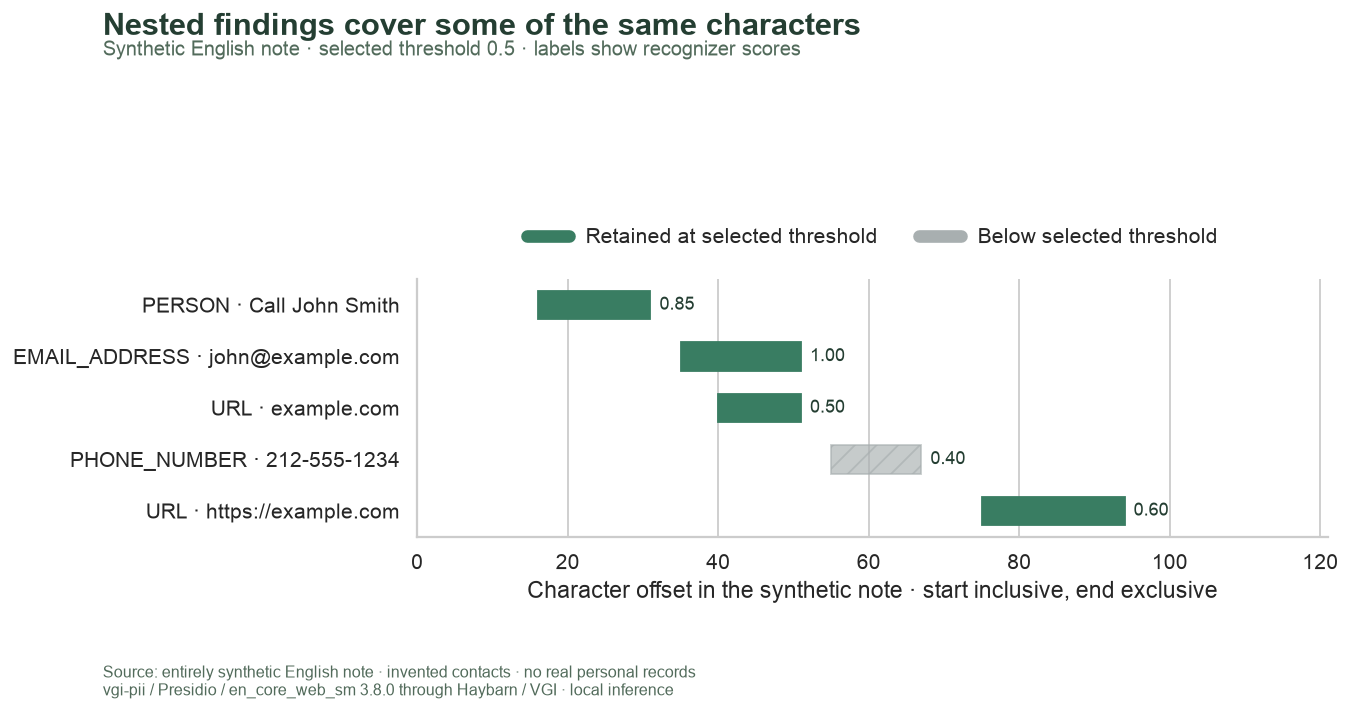

In [7]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for i, row in enumerate(spans.itertuples()):
    color = "#397d62" if row.retained else "#a8afb0"
    ax.barh(
        i,
        row.end_pos - row.start,
        left=row.start,
        height=0.55,
        color=color,
        edgecolor=color,
        hatch=None if row.retained else "//",
        alpha=1 if row.retained else 0.65,
    )
    ax.text(row.end_pos + 1.2, i, f"{row.score:.2f}", va="center", fontsize=10, color="#243e32")
ax.set_yticks(range(len(spans)), [f"{r.entity_type} · {r.text}" for r in spans.itertuples()])
ax.invert_yaxis()
ax.set_xlim(0, len(Path("fixtures/synthetic_note.txt").read_text()))
ax.set_xlabel("Character offset in the synthetic note · start inclusive, end exclusive")
ax.grid(axis="y", visible=False)
ax.legend(
    handles=[
        Line2D([0], [0], color="#397d62", lw=7, label="Retained at selected threshold"),
        Line2D([0], [0], color="#a8afb0", lw=7, label="Below selected threshold"),
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, 1.05),
    ncol=2,
    frameon=False,
)
finish(
    fig,
    f"spans-{SCORE_THRESHOLD:g}",
    "Nested findings cover some of the same characters",
    f"Synthetic English note · selected threshold {SCORE_THRESHOLD:g} · labels show recognizer scores",
)

In [8]:
%%sql totals <<
SELECT *,summed_span_characters-unique_covered_characters AS duplicate_character_counts,
 round(100.0*unique_covered_characters/note_characters,1) AS covered_percent FROM summary;

In [9]:
display(totals)
s = totals.iloc[0]
display(
    Markdown(
        f"At threshold **{SCORE_THRESHOLD:g}**, the worker returns **{int(s.selected_count)}** of "
        f"**{int(s.candidate_count)}** candidate spans. "
        f"Their lengths sum to **{int(s.summed_span_characters)} characters**, "
        f"but the union covers **{int(s.unique_covered_characters)} of {int(s.note_characters)} characters** "
        f"({s.covered_percent:.1f}%). Adding lengths would count **{int(s.duplicate_character_counts)} overlapping "
        "characters again. Coverage describes detector output; it does not measure the fraction of true "
        "sensitive information removed."
    )
)

,candidate_count,selected_count,summed_span_characters,unique_covered_characters,note_characters,duplicate_character_counts,covered_percent
0,5,4,61.0,50,121,11.0,41.3


At threshold **0.5**, the worker returns **4** of **5** candidate spans. Their lengths sum to **61 characters**, but the union covers **50 of 121 characters** (41.3%). Adding lengths would count **11 overlapping characters again. Coverage describes detector output; it does not measure the fraction of true sensitive information removed.

## Compare thresholds on the same candidate set

For each displayed threshold, SQL retains candidates with `score >= threshold`, expands their character intervals and counts distinct positions. This is a sensitivity curve from one materialized response, not repeated calls or a population performance estimate. The independently retrieved selected response must match the corresponding candidate filter. The gap between summed lengths and their union is overlap, not extra protected text.

In [10]:
%%sql
CREATE TABLE thresholds AS
SELECT DISTINCT cutoff FROM (VALUES (0.0),(0.4),(0.5),(0.6),(0.85),(0.9),(1.0),({{SCORE_THRESHOLD}})) AS v(cutoff);
CREATE TABLE sensitivity AS
SELECT t.cutoff,count(c.entity_type) AS detection_count,
 coalesce(sum(c.end_pos-c.start),0) AS summed_span_characters,
 (SELECT count(DISTINCT pos) FROM candidates k,range(k.start,k.end_pos) AS p(pos)
  WHERE k.score>=t.cutoff) AS unique_covered_characters
FROM thresholds t LEFT JOIN candidates c ON c.score>=t.cutoff GROUP BY t.cutoff;

,Count


In [11]:
%%sql curve <<
SELECT * FROM sensitivity ORDER BY cutoff;

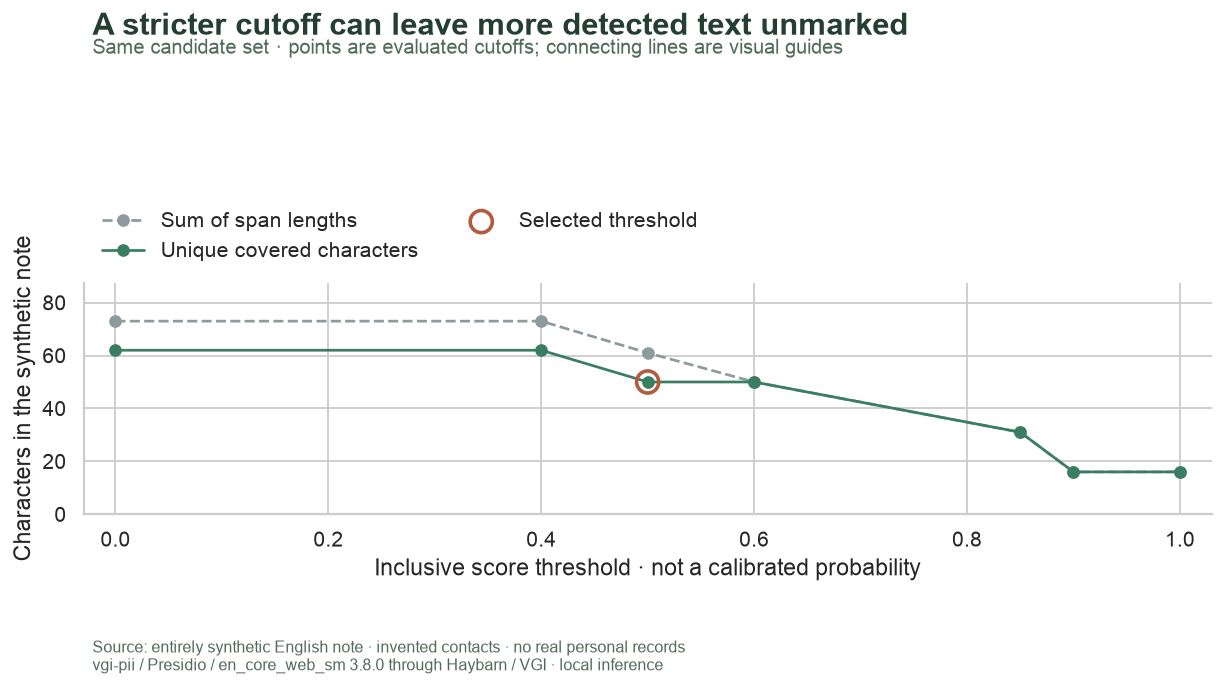

In [12]:
fig, ax = plt.subplots(figsize=(10, 5.3))
ax.plot(curve.cutoff, curve.summed_span_characters, "o--", color="#8c9b9d", label="Sum of span lengths")
ax.plot(curve.cutoff, curve.unique_covered_characters, "o-", color="#397d62", label="Unique covered characters")
selected_row = curve.loc[(curve.cutoff - SCORE_THRESHOLD).abs() < 1e-9].iloc[0]
ax.scatter(
    [SCORE_THRESHOLD],
    [selected_row.unique_covered_characters],
    s=150,
    facecolors="none",
    edgecolors="#b25b3f",
    linewidths=2,
    zorder=4,
    label="Selected threshold",
)
ax.set(
    xlabel="Inclusive score threshold · not a calibrated probability",
    ylabel="Characters in the synthetic note",
    ylim=(0, float(curve.summed_span_characters.max()) * 1.2),
    xlim=(-0.03, 1.03),
)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2, frameon=False)
finish(
    fig,
    f"coverage-{SCORE_THRESHOLD:g}",
    "A stricter cutoff can leave more detected text unmarked",
    "Same candidate set · points are evaluated cutoffs; connecting lines are visual guides",
)

## Read the scalar outputs at their fixed threshold

The next table comes from **fixed-0.5** per-row scalar functions. Changing `SCORE_THRESHOLD` above does **not** configure these functions. Tags replace accepted entities with their types; the function named `anonymize` masks accepted spans with asterisks. Masking retains text structure and can retain length, so the name is not a guarantee of irreversible anonymity. Overlapping detections need not produce one tag per returned span.

NULL and empty input produce NULL outputs. The clean control should be returned unchanged. For arbitrary text, an unchanged result can mean no accepted finding **or an analyzer error**: this worker deliberately catches per-call errors and degrades to unchanged text / no detections. Neither outcome certifies absence of PII. The synthetic note itself is a positive startup control.

In [13]:
%%sql outputs <<
SELECT input_kind,has_detection,entity_types,tagged,masked FROM scalar_results ORDER BY input_kind;

In [14]:
display(outputs)
row = outputs.loc[outputs.input_kind == "synthetic note"].iloc[0]
display(
    Markdown(
        "**Fixed-0.5 tagged output:**\n\n```text\n" + row.tagged + "\n```\n\n"
        "Compare this unchanged scalar output when rerunning at 0.9. "
        "In particular, inspect the unmasked demonstration phone "
        "string and the PERSON span’s boundaries; thresholding and model boundaries answer different questions."
    )
)

,input_kind,has_detection,entity_types,tagged,masked
0,NULL control,<NA>,<NA>,None,None
1,clean control,False,[],the quick brown fox,the quick brown fox
2,empty control,<NA>,<NA>,None,None
3,synthetic note,True,"[EMAIL_ADDRESS, PERSON, URL]",Synthetic note: <PERSON> at <EMAIL_ADDRESS> or...,Synthetic note: *************** at ***********...


**Fixed-0.5 tagged output:**

```text
Synthetic note: <PERSON> at <EMAIL_ADDRESS> or 212-555-1234. Visit <URL>. The delivery box is blue.
```

Compare this unchanged scalar output when rerunning at 0.9. In particular, inspect the unmasked demonstration phone string and the PERSON span’s boundaries; thresholding and model boundaries answer different questions.

## Check relationships, not a desired accuracy score

The checks verify substring reconstruction, bounds, score filtering, unique coverage, catalog membership and documented NULL behavior. The positive synthetic control checks that known example detections are present, but cannot prove the analyzer will succeed on other inputs.

In [15]:
%%sql checks <<
SELECT 'offsets reconstruct returned text' AS check_name,
 (SELECT bool_and(substr(n.body,c.start+1,c.end_pos-c.start)=c.text) FROM candidates c CROSS JOIN note n) AS passed
UNION ALL SELECT 'offsets stay within note',
 (SELECT bool_and(start>=0 AND end_pos>start AND end_pos<=length(body)) FROM candidates CROSS JOIN note)
UNION ALL SELECT 'scores lie in unit interval',(SELECT bool_and(score BETWEEN 0 AND 1) FROM candidates)
UNION ALL SELECT 'entity types exist in catalog',NOT EXISTS(SELECT 1 FROM candidates c ANTI JOIN supported s USING(entity_type))
UNION ALL SELECT 'candidate identities are unique',
 (SELECT count(*)=count(DISTINCT(entity_type,start,end_pos)) FROM candidates)
UNION ALL SELECT 'selected set equals score filter',
 NOT EXISTS((SELECT * FROM selected EXCEPT SELECT * FROM candidates WHERE score>={{SCORE_THRESHOLD}})
 UNION ALL (SELECT * FROM candidates WHERE score>={{SCORE_THRESHOLD}} EXCEPT SELECT * FROM selected))
UNION ALL SELECT 'union does not exceed summed lengths',
 (SELECT unique_covered_characters<=summed_span_characters AND unique_covered_characters<=note_characters FROM summary)
UNION ALL SELECT 'coverage never rises with threshold',
 (SELECT bool_and(previous IS NULL OR unique_covered_characters<=previous)
 FROM(SELECT *,lag(unique_covered_characters) OVER(ORDER BY cutoff) AS previous FROM sensitivity))
UNION ALL SELECT 'selected coverage agrees with curve',
 (SELECT c.unique_covered_characters=s.unique_covered_characters FROM sensitivity c CROSS JOIN summary s
 WHERE c.cutoff={{SCORE_THRESHOLD}})
UNION ALL SELECT 'NULL and empty scalar inputs stay NULL',
 (SELECT bool_and(has_detection IS NULL AND entity_types IS NULL AND tagged IS NULL AND masked IS NULL)
 FROM scalar_results WHERE input_kind IN ('NULL control','empty control'))
UNION ALL SELECT 'clean control remains unchanged',
 (SELECT NOT has_detection AND len(entity_types)=0 AND tagged=body AND masked=body FROM scalar_results
 WHERE input_kind='clean control')
UNION ALL SELECT 'positive example detects email and name',
 (SELECT has_detection AND list_contains(entity_types,'EMAIL_ADDRESS') AND list_contains(entity_types,'PERSON')
 FROM scalar_results WHERE input_kind='synthetic note');

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks
assert Path("fixtures/synthetic_note.txt").read_text() == connection.execute("SELECT body FROM note").fetchone()[0]
display(
    Markdown(f"**{len(checks)} SQL checks passed**, and the visible SQL note matches its committed provenance asset.")
)

,check_name,passed
0,offsets reconstruct returned text,True
1,offsets stay within note,True
2,scores lie in unit interval,True
3,entity types exist in catalog,True
4,candidate identities are unique,True
5,selected set equals score filter,True
6,union does not exceed summed lengths,True
7,coverage never rises with threshold,True
8,selected coverage agrees with curve,True
9,NULL and empty scalar inputs stay NULL,True


**12 SQL checks passed**, and the visible SQL note matches its committed provenance asset.

## Focused experiment: raise the review threshold

Change only **`SCORE_THRESHOLD` from 0.5 to 0.9**, restart and run all. Predict fewer retained spans and less unique character coverage. Compare the span chart, coverage table and fixed-0.5 tagged output: the scalar output should remain the same.

A stricter review cutoff is not a stricter redactor. The experiment isolates confidence filtering on one synthetic note, not false-positive/false-negative rates or a production privacy policy. Restore **0.5** for the saved baseline. The README command saves the experiment separately.

In [17]:
connection.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>